In [1]:
import json, folium, datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import pyarrow.parquet as pq
from functools import reduce
from glob import glob
from os.path import join
from multiprocessing import Pool
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.measures import individual
from skmob.preprocessing import filtering, compression, detection, clustering
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
base_path = ""
key_file = ""
daily_files = sorted(glob(join(base_path, "veraset*")))

In [3]:
def get_row_groups(row_group, files):
    """ Read a specific row group across all files. """
    
    return pd.concat([pq.ParquetFile(f, metadata=m).read_row_group(row_group).to_pandas() for f, m in zip(files, meta)]) 

def get_row_group_trajectories(row_group, files):
    """ Read the row group from all files and return a skmobility Trajectory DataFrame """
    df = get_row_groups(row_group, files)
    tdf = TrajDataFrame(df.reset_index(), latitude='latitude', longitude='longitude', datetime='datetime', user_id='caid')
    
    return tdf

def get_home_location(row_group, files):
    """ Read the row group from all files and return the home location of each user. """

    tdf = get_row_group_trajectories(row_group, files)
    
    return individual.home_location(tdf, show_progress=False)

In [4]:
meta = [pq.ParquetFile(x).metadata for x in daily_files]
row_groups = np.arange(0, 10) #57431
files = [daily_files] * len(row_groups)
args = [(rg, f) for rg, f in zip(row_groups, files)]

In [5]:
%%time
with Pool(processes=8) as pool:
    tdf = pd.concat(pool.starmap(get_row_group_trajectories, args))
tdf.head(3)

CPU times: user 165 ms, sys: 932 ms, total: 1.1 s
Wall time: 3.64 s


,uid,datetime,id_type,lat,lng,horizontal_accuracy
0,0000332b899e1497d89f0011bb2057f5e0c6d3ac4cccf3...,2024-03-14 22:59:00-07:00,idfa,33.7267,-118.000778,10
1,0000332b899e1497d89f0011bb2057f5e0c6d3ac4cccf3...,2024-03-14 22:59:03-07:00,idfa,33.7267,-118.000771,10
2,0000332b899e1497d89f0011bb2057f5e0c6d3ac4cccf3...,2024-03-14 22:59:10-07:00,idfa,33.7267,-118.000748,10


for all users

1. filter
2. compress
3. compute stops
4. calculate trajectories to stops
5. map travel with ability to scroll through time
6. create grid of input variables with gridded output plots

########### FILTERING ##########
  
  mobility_filter:
    
    max_speed_kmh: 500.0
    include_loops: False
    speed_kmh: 5.0
    max_loop: 6
    ratio_max: 0.25

  compress:
    
    spatial_radius_km: 0.2

########### INDIVIDUAL MEASURES ##########
  
  radius_of_gyration:
  
    show_progress: False  
  
  home_location:
    
    start_night: '22:00'
    end_night: '07:00'
    show_progress: False

  jump_lengths:
    
    show_progress: False
    merge: False

  max_distance_from_home:
  
    start_night: '22:00'
    end_night: '07:00'
    show_progress: False

In [6]:
tdf_fltr = filtering.filter(tdf,
                            max_speed_kmh=500.,
                            include_loops=False,
                            speed_kmh=5.0,
                            max_loop=6,
                            ratio_max=0.25)

In [7]:
tdf_fltr_comp = compression.compress(tdf_fltr,
                                     spatial_radius_km=0.2)

In [8]:
tdf_rg = individual.radius_of_gyration(tdf_fltr_comp,
                                       show_progress=False)

In [9]:
tdf_hl = individual.home_location(tdf_fltr_comp,
                                  start_night='22:00',
                                  end_night='07:00',
                                  show_progress=False)

In [10]:
tdf_jl = individual.jump_lengths(tdf_fltr_comp,
                                 show_progress=False,
                                 merge=False)

In [11]:
tdf_mdh = individual.max_distance_from_home(tdf_fltr_comp,
                                            start_night='22:00',
                                            end_night='07:00',
                                            show_progress=False)

In [29]:
dfs = [tdf_rg, tdf_jl, tdf_hl, tdf_mdh]
merged_df = reduce(lambda left, right: pd.merge(left, right, on='uid', how='outer'), dfs)
merged_df.set_index('uid', inplace=True)
merged_df.tail(5)

,radius_of_gyration,jump_lengths,lat,lng,max_distance_from_home
uid,,,,,
000b193e01dfd429b66783147229af7fae49707805cb1c514ac8deedb2dbfede,0.000000,[],37.405941,-122.078583,0.000000
000b193e99af54ea3434e3f7583dca5a826119d29650f5070ee3db3a0a2955da,6.397715,[12.79542995413909],34.006199,-117.443199,12.795430
000b19f58166c94ef9a4172d7dbfc607ef7181074f78f37fb3229b4b15c26540,5.969774,"[2.8561583695327846, 23.677966543326757, 16.30...",37.952847,-122.367950,22.942112
000b1ad22f5901a6b5b730b681c4f650b32b8aa745e15043fac823d130b094b3,2.159121,[4.318241657003665],34.885818,-117.017708,4.318242
000b1bf559cd267558bc9ff3b1c3f3d3fae9991557db339d1ab0ecbc95251b24,0.000000,[],34.141521,-118.248688,0.000000


In [30]:
batch_output = pd.read_parquet("/glade/derecho/scratch/ggantos/cat-rain-output/veraset_2024-03-14_2024-04-30.parquet", engine='pyarrow')
batch_output.set_index('uid', inplace=True)
batch_output.tail()

,radius_of_gyration,jump_lengths,lat,lng,max_distance_from_home
uid,,,,,
000b193e01dfd429b66783147229af7fae49707805cb1c514ac8deedb2dbfede,0.000000,[],37.405941,-122.078583,0.000000
000b193e99af54ea3434e3f7583dca5a826119d29650f5070ee3db3a0a2955da,6.397715,[12.79542995413909],34.006199,-117.443199,12.795430
000b19f58166c94ef9a4172d7dbfc607ef7181074f78f37fb3229b4b15c26540,5.969774,"[2.8561583695327846, 23.677966543326757, 16.30...",37.952847,-122.367950,22.942112
000b1ad22f5901a6b5b730b681c4f650b32b8aa745e15043fac823d130b094b3,2.159121,[4.318241657003665],34.885818,-117.017708,4.318242
000b1bf559cd267558bc9ff3b1c3f3d3fae9991557db339d1ab0ecbc95251b24,0.000000,[],34.141521,-118.248688,0.000000


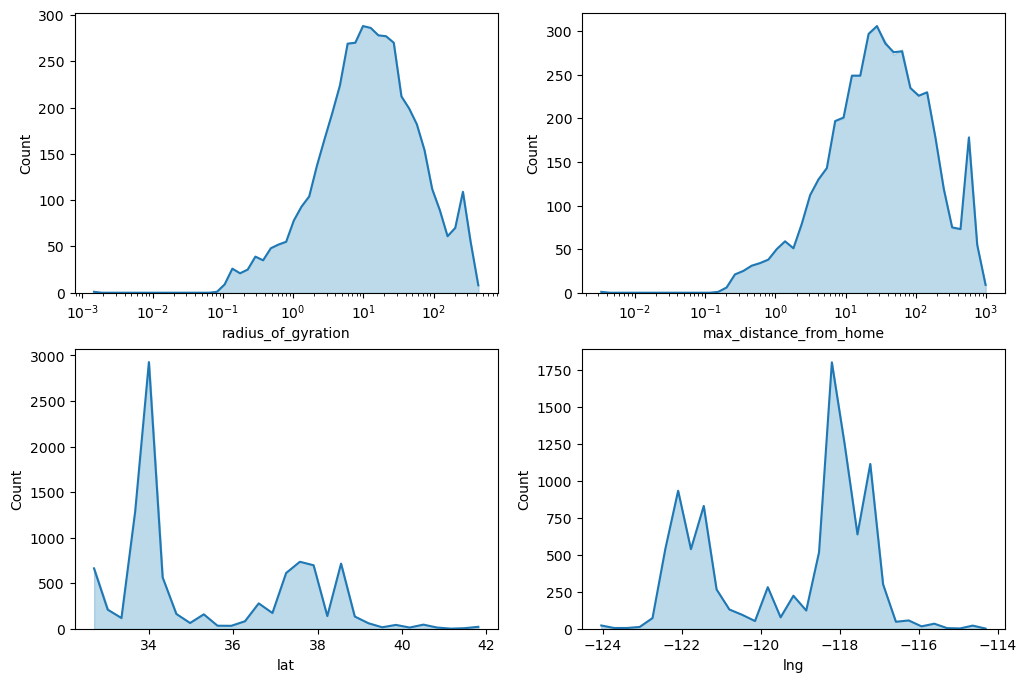

In [31]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

colors = sns.color_palette("Paired")[:2]

sns.histplot(data=merged_df, x="radius_of_gyration", ax=axes[0,0], color=colors[0], element="poly", stat="count", log_scale=True)
sns.histplot(data=batch_output, x="radius_of_gyration", ax=axes[0,0], color=colors[1], element="poly", stat="count", log_scale=True, fill=False)
sns.histplot(data=merged_df, x="max_distance_from_home", ax=axes[0,1], color=colors[0], element="poly", stat="count", log_scale=True)
sns.histplot(data=batch_output, x="max_distance_from_home", ax=axes[0,1], color=colors[1], element="poly", stat="count", log_scale=True, fill=False)
sns.histplot(data=merged_df, x="lat", ax=axes[1,0], color=colors[0], element="poly", stat="count")
sns.histplot(data=batch_output, x="lat", ax=axes[1,0], color=colors[1], element="poly", stat="count", fill=False)
sns.histplot(data=merged_df, x="lng", ax=axes[1,1], color=colors[0], element="poly", stat="count")
sns.histplot(data=batch_output, x="lng", ax=axes[1,1], color=colors[1], element="poly", stat="count", fill=False)

fig.show()

In [33]:
deltas.head(5)

,max_distance_from_home,radius_of_gyration,lat,lng
uid,,,,
0000001895b021c56bb407ea8c4743ed3eeea48272a3ef0e91fd3687b31beedd,0.0,0.0,0.0,0.0
000000aa47ce287ef4af544f71ee749f7b23ee1cd2c9988b677c49f221158d04,0.0,0.0,0.0,0.0
00000100fad94dbbd2bf0e74d6bdc4782c4e7207d6d9e3d948916f601ca3b77b,0.0,0.0,0.0,0.0
0000019a8d62587a1063194cc9353fb814522e03b0e523bd47baffbbdd47aba5,0.0,0.0,0.0,0.0
000001be5106d94ed20c1dfc8b126f45606196d0c5482d38a4368217452a9869,0.0,0.0,0.0,0.0


In [32]:
columns = ["max_distance_from_home", "radius_of_gyration", "lat", "lng"]
deltas = batch_output[columns].subtract(merged_df[columns])
deltas.sum().sum()

-30.324947499041407

In [34]:
for column in columns:
    print("batch\n", batch_output[column][:10])
    print("notebook\n", merged_df[column][:10])
    delta = batch_output[column].sub(merged_df[column])
    print("delta\n", delta[:10])
    print("TOTAL:", delta.sum())

batch
 uid
0000001895b021c56bb407ea8c4743ed3eeea48272a3ef0e91fd3687b31beedd     0.000000
000000aa47ce287ef4af544f71ee749f7b23ee1cd2c9988b677c49f221158d04     0.000000
00000100fad94dbbd2bf0e74d6bdc4782c4e7207d6d9e3d948916f601ca3b77b     0.000000
0000019a8d62587a1063194cc9353fb814522e03b0e523bd47baffbbdd47aba5     4.379818
000001be5106d94ed20c1dfc8b126f45606196d0c5482d38a4368217452a9869     0.000000
0000021a9597e80d75debb8e01e7d96b1573fe702b8d87dd77d3bee38d31d5ef    13.917434
0000021c82b238e4fb7464523fe63ba2d562d598673057db4c82db0d6175fc26     0.000000
00000236ce9fc5e50cc40b9ce5eee0c5072dc7770196a23649959c51afc59a1d     0.000000
0000023841efdafa5bbe3951e29d8eb70a4b136075d2995903beb8c9c780ef67     0.000000
00000273c1c774261bc0cae69b0903bb52e580ca135094f6c6d28d0af6eb935a     0.000000
Name: max_distance_from_home, dtype: float64
notebook
 uid
0000001895b021c56bb407ea8c4743ed3eeea48272a3ef0e91fd3687b31beedd     0.000000
000000aa47ce287ef4af544f71ee749f7b23ee1cd2c9988b677c49f221158d04     0.0

In [35]:
merged_df[columns].describe()

,max_distance_from_home,radius_of_gyration,lat,lng
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,41.381344,16.326528,35.386983,-119.283239
std,111.763178,46.232169,2.058025,1.952741
min,0.000000,0.000000,32.550446,-124.204964
25%,0.000000,0.000000,33.881655,-121.405296
50%,0.000000,0.000000,34.124437,-118.304657
75%,24.708257,9.755323,37.450720,-117.822503
max,1123.606659,487.263436,41.969471,-114.141151


In [36]:
batch_output[columns].describe()

,max_distance_from_home,radius_of_gyration,lat,lng
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,41.379297,16.326528,35.384251,-119.281491
std,111.747728,46.232169,2.056528,1.952801
min,0.000000,0.000000,32.544643,-124.204964
25%,0.000000,0.000000,33.879144,-121.405296
50%,0.000000,0.000000,34.122383,-118.303120
75%,24.708257,9.755323,37.442060,-117.819099
max,1123.606659,487.263436,41.969471,-114.141151


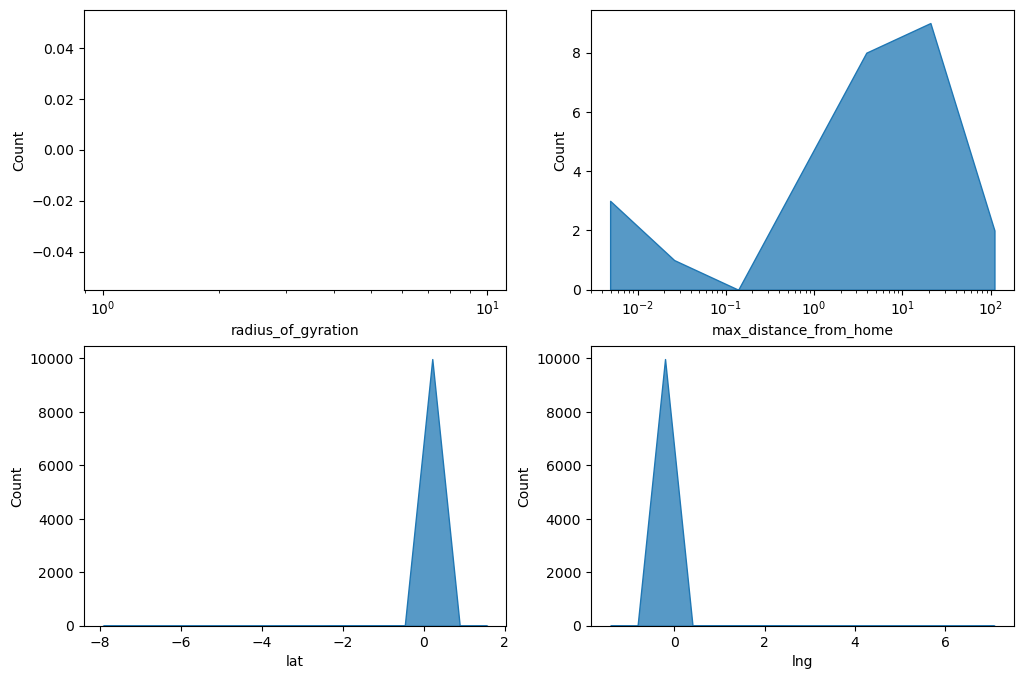

In [37]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

sns.histplot(data=deltas, x="radius_of_gyration", ax=axes[0,0], element="poly", stat="count", log_scale=True)
sns.histplot(data=deltas, x="max_distance_from_home", ax=axes[0,1], element="poly", stat="count", log_scale=True)
sns.histplot(data=deltas, x="lat", ax=axes[1,0], element="poly", stat="count")
sns.histplot(data=deltas, x="lng", ax=axes[1,1], element="poly", stat="count")

fig.show()